# Customer Churn Predictor
**PSEB Artificial Intelligence Bootcamp – Business ML Portfolio Project**

This notebook follows the 11 steps in the project brief. Each step has its own section and executable code cell. The objective is to understand why telecom customers leave, train a model that identifies customers at risk, and prepare a model for the Streamlit application.

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns).  
**Target:** `Churn` (`Yes` = customer leaves, `No` = customer stays).

> Run the notebook from top to bottom. In Google Colab, upload `Telco-Customer-Churn.csv` when prompted. The notebook saves the trained pipeline as `churn_model.joblib` for the app.


## 1. Load the dataset
Load the supplied CSV. If it is not present in the working directory, Colab will ask you to upload it.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

DATA_PATH = Path("/content/Telco-Customer-Churn (1).csv")
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Dataset loaded: /content/Telco-Customer-Churn (1).csv
Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. First look: shape, data types and duplicates
Inspect the dataset before cleaning. This helps identify data-quality issues.

In [2]:
print("Dataset shape:", df.shape)
print("\nColumn data types:")
display(df.dtypes.rename("Data type").to_frame())
print("\nMissing values by column:")
display(df.isna().sum().rename("Missing values").to_frame())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("\nTarget distribution:")
display(df["Churn"].value_counts().rename("Customers").to_frame())
print("\nTarget percentage:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())


Dataset shape: (7043, 21)

Column data types:


,Data type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values by column:


,Missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0
Duplicate customer IDs: 0

Target distribution:


,Customers
Churn,
No,5174
Yes,1869



Target percentage:


,Percentage
Churn,
No,73.46
Yes,26.54


## 3. Clean the data
`TotalCharges` is stored as text and contains 11 blank strings. Convert it to numeric, handle those blanks, and remove `customerID` because it is an identifier rather than a useful predictive feature.

In [3]:
df_clean = df.copy()

# Convert blank strings to missing values, then convert the column to numeric.
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip().replace("", np.nan),
    errors="coerce"
)

print("Missing TotalCharges after conversion:", df_clean["TotalCharges"].isna().sum())

# The blank TotalCharges rows correspond to customers with zero tenure.
# Fill with 0 because no tenure means no accumulated charges.
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Remove the customer identifier.
df_clean = df_clean.drop(columns=["customerID"])

print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", int(df_clean.isna().sum().sum()))
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
display(df_clean.head())


Missing TotalCharges after conversion: 11
Cleaned shape: (7043, 20)
Remaining missing values: 0
TotalCharges dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Exploratory data analysis (EDA)
Explore churn by contract, tenure, monthly bill and payment method. These views help translate model results into business actions.

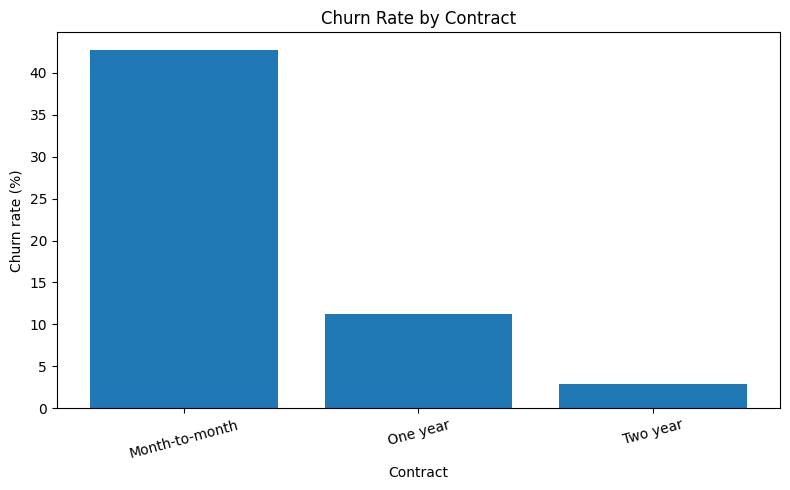

,Churn rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [4]:
eda_df = df_clean.copy()
eda_df["ChurnLabel"] = eda_df["Churn"].map({"Yes": "Churned", "No": "Stayed"})

# Churn rate by contract type.
contract_churn = (
    eda_df.groupby("Contract", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
plt.figure(figsize=(8, 5))
plt.bar(contract_churn.index.astype(str), contract_churn.values)
plt.title("Churn Rate by Contract")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
display(contract_churn.round(2).rename("Churn rate (%)").to_frame())


### 4A. Churn by tenure

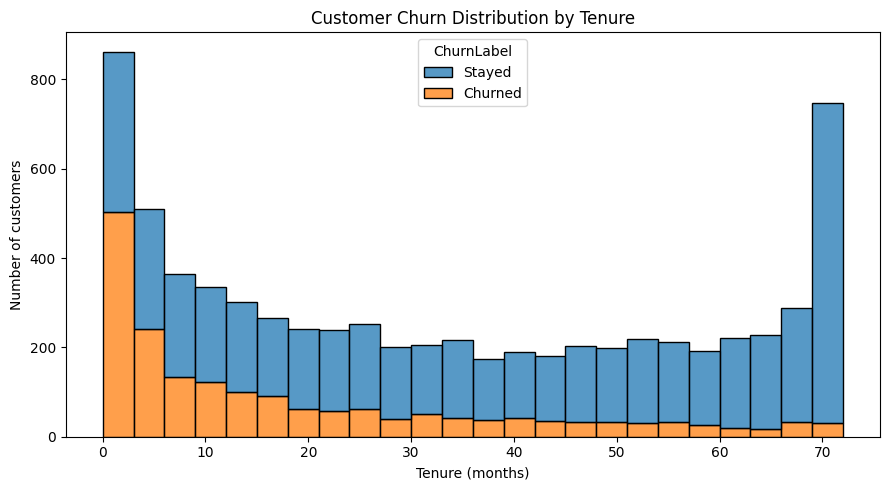

,Churn rate (%)
tenure,
0–12,47.44
13–24,28.71
25–48,20.39
49–72,9.51


In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=eda_df, x="tenure", hue="ChurnLabel",
    bins=24, multiple="stack", kde=False
)
plt.title("Customer Churn Distribution by Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

tenure_bins = pd.cut(
    eda_df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
)
tenure_churn = eda_df.groupby(tenure_bins, observed=False)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)
display(tenure_churn.round(2).rename("Churn rate (%)").to_frame())


### 4B. Churn by monthly charges

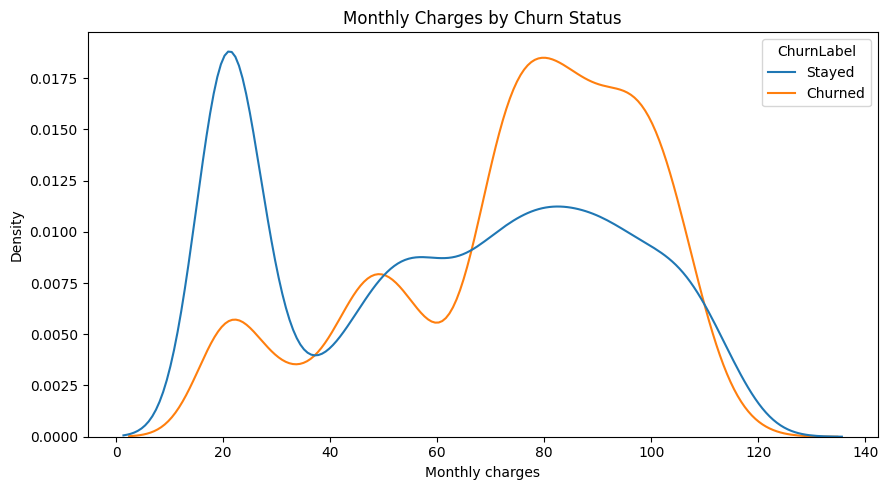

,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869


In [6]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=eda_df, x="MonthlyCharges", hue="ChurnLabel", common_norm=False)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Monthly charges")
plt.tight_layout()
plt.show()

monthly_summary = eda_df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median", "count"])
display(monthly_summary.round(2))


### 4C. Churn by payment method

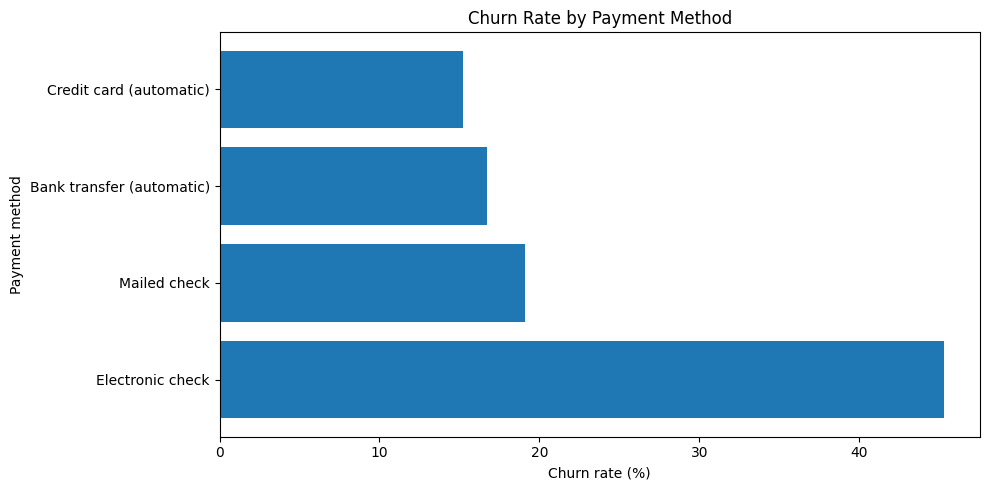

,Churn rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


In [7]:
payment_churn = (
    eda_df.groupby("PaymentMethod", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
plt.figure(figsize=(10, 5))
plt.barh(payment_churn.index.astype(str), payment_churn.values)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn rate (%)")
plt.ylabel("Payment method")
plt.tight_layout()
plt.show()
display(payment_churn.round(2).rename("Churn rate (%)").to_frame())


## 5. Prepare the data: 80/20 stratified split
Separate the target from the features. Stratification keeps the churn proportion similar in the training and test sets.

In [8]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nOverall churn rate:", round(y.mean() * 100, 2), "%")
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training rows: 5634
Testing rows: 1409

Overall churn rate: 26.54 %
Training churn rate: 26.54 %
Testing churn rate: 26.54 %


## 6. Build the preprocessing pipeline
Scale numerical features and one-hot encode categorical features. The transformations are fitted only on training data through the pipeline, preventing data leakage.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessor is ready.")


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Preprocessor is ready.


## 7. Compare three classification models
Train Logistic Regression, Decision Tree and Random Forest using the same preprocessing pipeline. The models use balanced class weights to give the minority churn class more attention.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=300, random_state=42, n_jobs=-1
    )
}

comparison_rows = []
fitted_models = {}

for model_name, classifier in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)
    probabilities = model_pipeline.predict_proba(X_test)[:, 1]

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })
    fitted_models[model_name] = model_pipeline

comparison_df = pd.DataFrame(comparison_rows).set_index("Model").sort_values(
    "Recall", ascending=False
)
display(comparison_df.round(3))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.842
Decision Tree,0.732,0.495,0.487,0.491,0.654
Random Forest,0.784,0.621,0.473,0.537,0.823


## 8. Focus on recall
Recall measures the proportion of actual churners that the model correctly identifies. A false negative is a customer who leaves but was not flagged, so recall is an important metric for this business problem.

In [11]:
best_model_name = comparison_df["Recall"].idxmax()
print("Highest test-set recall before tuning:", best_model_name)
print("\nRecall comparison:")
display(comparison_df[["Recall", "Precision", "F1-score"]].round(3))

# The balanced class weights are already included in all three model definitions.
print("\nAll compared classifiers use class_weight='balanced'.")


Highest test-set recall before tuning: Logistic Regression

Recall comparison:


,Recall,Precision,F1-score
Model,,,
Logistic Regression,0.783,0.504,0.614
Decision Tree,0.487,0.495,0.491
Random Forest,0.473,0.621,0.537



All compared classifiers use class_weight='balanced'.


## 9. Tune the selected model with GridSearchCV
Choose the model with the highest initial recall and tune a compact parameter grid using stratified cross-validation on the training data only. The scoring objective is recall.

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

selected_classifier = models[best_model_name]
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", selected_classifier)
])

if best_model_name == "Logistic Regression":
    param_grid = {
        "classifier__C": [0.1, 1, 5, 10],
        "classifier__solver": ["liblinear"]
    }
elif best_model_name == "Decision Tree":
    param_grid = {
        "classifier__max_depth": [3, 5, 8, None],
        "classifier__min_samples_leaf": [1, 5, 10]
    }
else:
    param_grid = {
        "classifier__n_estimators": [200, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 3]
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Selected model:", best_model_name)
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation recall:", round(grid_search.best_score_, 3))


Fitting 5 folds for each of 4 candidates, totalling 20 fits
Selected model: Logistic Regression
Best parameters: {'classifier__C': 1, 'classifier__solver': 'liblinear'}
Best cross-validation recall: 0.801


## 10. Evaluate on unseen test data
Use the tuned model to generate the confusion matrix and classification report. The test set has not been used to fit or tune the model.

Final test metrics
Accuracy: 0.738
Precision: 0.504
Recall: 0.783
F1-score: 0.614
ROC-AUC: 0.842

Classification report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



,Predicted stayed,Predicted churned
Actual stayed,747,288
Actual churned,81,293


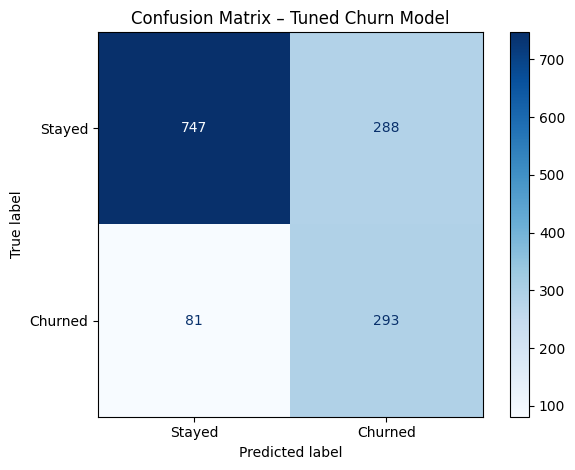

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

print("Final test metrics")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual stayed", "Actual churned"],
    columns=["Predicted stayed", "Predicted churned"]
))
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Stayed", "Churned"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Tuned Churn Model")
plt.tight_layout()
plt.show()


## 11. Business recommendations
Generate recommendations from the dataset's measured churn rates. These are business actions to test; the analysis shows associations and does not prove that any single factor causes churn.

In [14]:
# Calculate the actual rates from the cleaned dataset.
contract_rates = (
    df_clean.groupby("Contract")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
payment_rates = (
    df_clean.groupby("PaymentMethod")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
first_year = df_clean.loc[df_clean["tenure"] <= 12, "Churn"]
first_year_rate = (first_year == "Yes").mean() * 100
overall_rate = (df_clean["Churn"] == "Yes").mean() * 100

print(f"Overall churn rate: {overall_rate:.1f}%")
print("\nContract churn rates (%):")
display(contract_rates.round(1).to_frame("Churn rate (%)"))
print("\nPayment method churn rates (%):")
display(payment_rates.round(1).to_frame("Churn rate (%)"))
print(f"Churn rate among customers with 12 months or less tenure: {first_year_rate:.1f}%")

print("\nRecommended actions to test:")
print("1. Prioritize early-tenure customers with onboarding calls and proactive support.")
print("2. Offer suitable longer-term contract incentives to month-to-month customers.")
print("3. Review the customer experience and payment friction for the highest-churn payment method.")
print("4. Create a weekly retention list from high-risk predictions and track save rate.")


Overall churn rate: 26.5%

Contract churn rates (%):


,Churn rate (%)
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8



Payment method churn rates (%):


,Churn rate (%)
PaymentMethod,
Electronic check,45.3
Mailed check,19.1
Bank transfer (automatic),16.7
Credit card (automatic),15.2


Churn rate among customers with 12 months or less tenure: 47.4%

Recommended actions to test:
1. Prioritize early-tenure customers with onboarding calls and proactive support.
2. Offer suitable longer-term contract incentives to month-to-month customers.
3. Review the customer experience and payment friction for the highest-churn payment method.
4. Create a weekly retention list from high-risk predictions and track save rate.


## 12. Save the trained model for the Streamlit app
Save the complete preprocessing-and-model pipeline. The app will load this single artifact, so it applies the same transformations used during training.

In [15]:
import joblib

MODEL_PATH = Path("churn_model.joblib")
joblib.dump(best_model, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH.resolve()}")
print("Model artifact size (KB):", round(MODEL_PATH.stat().st_size / 1024, 1))


Saved model to: /content/churn_model.joblib
Model artifact size (KB): 8.4


## 13. Final project checks
Confirm that the model artifact exists and that the app's expected input columns match the model training features.

In [16]:
assert MODEL_PATH.exists(), "Model file was not created."
assert list(X.columns) == list(best_model.feature_names_in_), "Feature columns do not match."
test_sample = X_test.iloc[[0]].copy()
sample_probability = best_model.predict_proba(test_sample)[0, 1]
print("Final checks passed.")
print("Sample churn probability:", round(float(sample_probability), 3))
print("Input feature count:", len(X.columns))


Final checks passed.
Sample churn probability: 0.118
Input feature count: 19
